# 🦟 VectorIA
## Análisis Exploratorio de Datos (EDA)
### Dataset 4: Kaggle — *Aedes aegypti* vs. *Aedes albopictus*

**Proyecto:** VectorIA — Asistente Inteligente para la Vigilancia del Dengue en Costa Rica  
**Módulo:** CNN — Identificación de mosquitos  
**Notebook:** `04_EDA_Kaggle.ipynb`  
**Fuente:** [Aedes Mosquitos — Kaggle](https://www.kaggle.com/datasets/pradeepisawasan/aedes-mosquitos)

**Objetivo:** explorar las imágenes de las dos clases, revisar su calidad e integridad y detectar riesgos para el posterior entrenamiento de la CNN, **sin modificar ni entrenar modelos**.



## 1. Importación de librerías

Se importan una sola vez las librerías para manejar rutas, analizar datos, leer imágenes y generar gráficos. `pathlib` y `hashlib` vienen con Python.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

## 2. Ubicación y estructura del dataset

Se establece directamente la ruta de la carpeta que contiene las subcarpetas `aegypti` y `albopictus` y se muestra su contenido. No es necesario volver a importar `Path`.

In [2]:
ruta = Path(r"C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\data\raw\mosquitos\Kaggle-aegypti_vs_albopictus")

print("Dataset Kaggle:", ruta)
print("\nContenido principal:")
for carpeta in sorted(ruta.iterdir()):
    print("[Carpeta]" if carpeta.is_dir() else "[Archivo]", carpeta.name)

Dataset Kaggle: C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\data\raw\mosquitos\Kaggle-aegypti_vs_albopictus

Contenido principal:
[Carpeta] aegypti
[Carpeta] albopictus


## 3. Inventario de imágenes y asignación de clases

Se enumeran los archivos de imagen y se asignan las etiquetas a partir de la **carpeta principal** en la que están guardados. También se identificarán imágenes fuera de las dos carpetas esperadas, si existen.

In [3]:
EXTENSIONES_IMAGEN = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}
CLASES = ["aegypti", "albopictus"]
registros = []

for archivo in sorted(ruta.rglob("*")):
    if not archivo.is_file() or archivo.suffix.lower() not in EXTENSIONES_IMAGEN:
        continue
    relativo = archivo.relative_to(ruta)
    primera_carpeta = relativo.parts[0].lower() if len(relativo.parts) > 1 else ""
    clase = primera_carpeta if primera_carpeta in CLASES else "SIN_CLASE"
    registros.append({
        "Clase": clase,
        "Nombre": archivo.name,
        "Ruta_relativa": str(relativo),
        "Extension": archivo.suffix.lower(),
        "Tamaño_MB": archivo.stat().st_size / (1024**2),
        "Archivo": archivo,
    })

df_imagenes = pd.DataFrame(
    registros, columns=["Clase", "Nombre", "Ruta_relativa", "Extension", "Tamaño_MB", "Archivo"]
)
print("Imágenes encontradas:", len(df_imagenes))
print("Imágenes sin clase identificada:", int((df_imagenes["Clase"] == "SIN_CLASE").sum()))
display(df_imagenes.drop(columns="Archivo").head(10))

Imágenes encontradas: 4803
Imágenes sin clase identificada: 0


,Clase,Nombre,Ruta_relativa,Extension,Tamaño_MB
0,aegypti,aegypti100a.jpg,aegypti\aegypti\aegypti_0\aegypti100a.jpg,.jpg,4.021219
1,aegypti,aegypti100b.jpg,aegypti\aegypti\aegypti_0\aegypti100b.jpg,.jpg,4.014118
2,aegypti,aegypti100c.jpg,aegypti\aegypti\aegypti_0\aegypti100c.jpg,.jpg,4.005596
3,aegypti,aegypti101b.jpg,aegypti\aegypti\aegypti_0\aegypti101b.jpg,.jpg,4.014976
4,aegypti,aegypti101c.jpg,aegypti\aegypti\aegypti_0\aegypti101c.jpg,.jpg,4.010736
5,aegypti,aegypti101d.jpg,aegypti\aegypti\aegypti_0\aegypti101d.jpg,.jpg,4.018113
6,aegypti,aegypti102a.jpg,aegypti\aegypti\aegypti_0\aegypti102a.jpg,.jpg,4.018883
7,aegypti,aegypti102b.jpg,aegypti\aegypti\aegypti_0\aegypti102b.jpg,.jpg,4.014557
8,aegypti,aegypti102c.jpg,aegypti\aegypti\aegypti_0\aegypti102c.jpg,.jpg,4.016918
9,aegypti,aegypti102d.jpg,aegypti\aegypti\aegypti_0\aegypti102d.jpg,.jpg,4.019243


## 4. Cantidad de imágenes por clase

Se cuenta el número de fotografías disponibles de *Aedes aegypti* y *Aedes albopictus* para conocer el tamaño real del conjunto.

In [4]:
conteo = df_imagenes["Clase"].value_counts().reindex(CLASES, fill_value=0)
tabla_conteo = conteo.rename_axis("Clase").reset_index(name="Imágenes")
display(tabla_conteo)
print("Total de imágenes:", len(df_imagenes))

,Clase,Imágenes
0,aegypti,2403
1,albopictus,2400


Total de imágenes: 4803


## 5. Distribución porcentual y desbalance inicial

Se calcula el porcentaje de cada especie y se grafica su frecuencia. La relación mayoritaria/minoritaria permitirá determinar si el conjunto está equilibrado.

,Clase,Imágenes,Porcentaje (%)
0,aegypti,2403,50.03
1,albopictus,2400,49.97


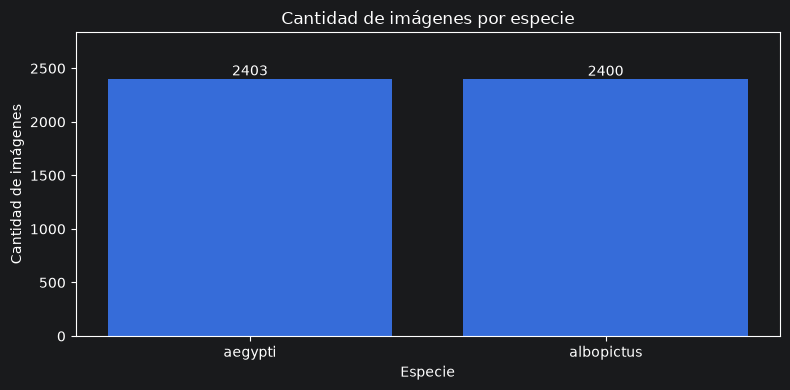

In [5]:
tabla_distribucion = tabla_conteo.copy()
tabla_distribucion["Porcentaje (%)"] = (
    100 * tabla_distribucion["Imágenes"] / max(len(df_imagenes), 1)
).round(2)
display(tabla_distribucion)

plt.figure(figsize=(8, 4))
barras = plt.bar(tabla_distribucion["Clase"], tabla_distribucion["Imágenes"])
for barra in barras:
    plt.text(barra.get_x() + barra.get_width()/2, barra.get_height(),
             str(int(barra.get_height())), ha="center", va="bottom")
plt.title("Cantidad de imágenes por especie")
plt.xlabel("Especie")
plt.ylabel("Cantidad de imágenes")
plt.ylim(0, max(tabla_distribucion["Imágenes"].max() * 1.18, 1))
plt.tight_layout()
plt.show()

## 6. Visualización de imágenes originales por especie

Se muestran ejemplos de cada clase para revisar las fotografías y observar fondos, encuadres, coloración e iluminación. La selección es reproducible y no modifica las imágenes.

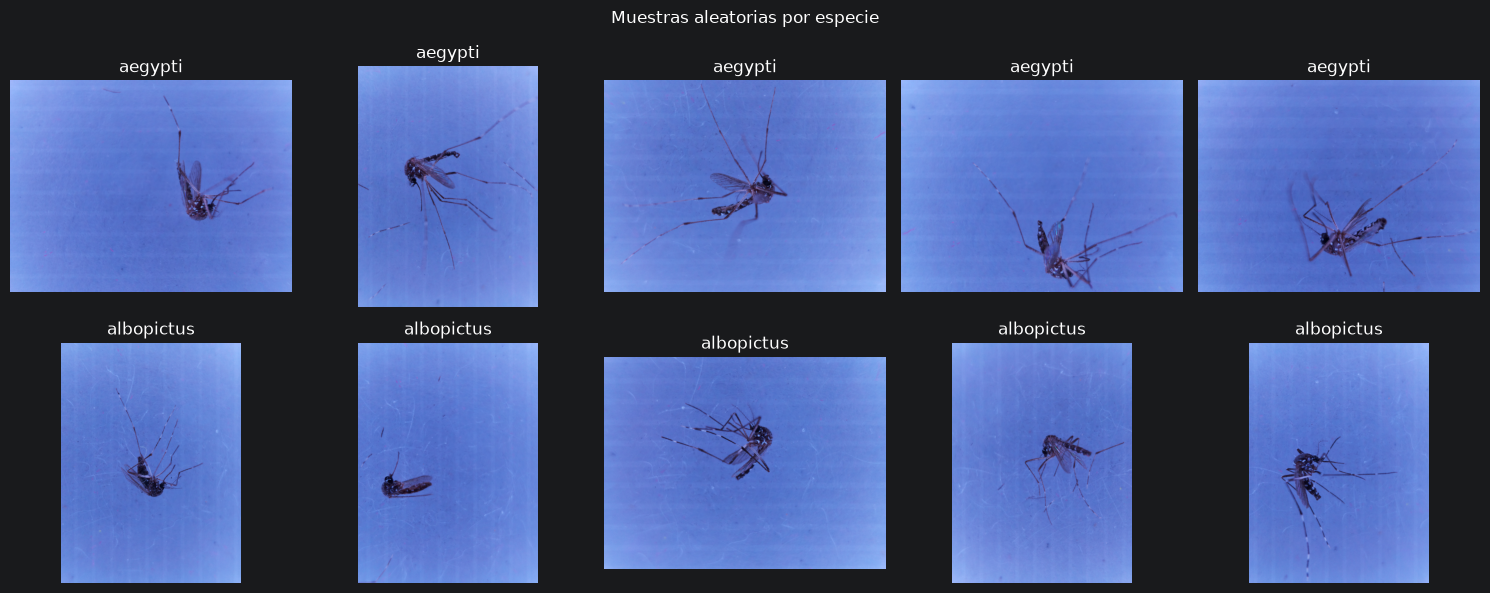

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for fila, clase in enumerate(CLASES):
    muestra = df_imagenes[df_imagenes["Clase"] == clase].sample(
        n=min(5, (df_imagenes["Clase"] == clase).sum()), random_state=42
    )
    for ax in axes[fila]:
        ax.axis("off")
    for ax, (_, reg) in zip(axes[fila], muestra.iterrows()):
        try:
            with Image.open(reg["Archivo"]) as img:
                ax.imshow(ImageOps.exif_transpose(img).convert("RGB"))
            ax.set_title(clase)
        except Exception:
            ax.set_title("No legible")
plt.suptitle("Muestras aleatorias por especie")
plt.tight_layout()
plt.show()

## 7. Integridad, metadatos y mediciones de calidad

Se verifica que las imágenes puedan leerse y se extraen sus dimensiones, formato real, modo de color, brillo, contraste, nitidez aproximada y hash perceptual.

**Criterios de medición:** brillo = media del gris (0–255); contraste = desviación estándar del gris; nitidez = varianza de un filtro Laplaciano aplicado a una miniatura de 128 × 128. Estas métricas ayudan a detectar casos a revisar, pero no sustituyen la inspección visual. Este paso puede tardar debido a la lectura de todas las fotografías.

In [7]:
def calcular_dhash(imagen):
    gris = imagen.convert("L").resize((9, 8))
    pix = np.asarray(gris, dtype=np.uint8)
    bits = (pix[:, 1:] > pix[:, :-1]).ravel()
    numero = 0
    for bit in bits:
        numero = (numero << 1) | int(bit)
    return f"{numero:016x}"

metadatos, errores = [], []
for _, registro in df_imagenes.iterrows():
    archivo = registro["Archivo"]
    try:
        with Image.open(archivo) as img:
            img.verify()
        with Image.open(archivo) as img:
            img.load()
            ancho, alto = img.size
            formato_real, modo = img.format, img.mode
            miniatura = img.convert("RGB").resize((128, 128))
            pix = np.asarray(miniatura.convert("L"), dtype=np.float32)
            brillo = float(pix.mean())
            contraste = float(pix.std())
            lap = (pix[:-2, 1:-1] + pix[2:, 1:-1] +
                   pix[1:-1, :-2] + pix[1:-1, 2:] - 4 * pix[1:-1, 1:-1])
            nitidez = float(lap.var())
            hash_visual = calcular_dhash(img)
        metadatos.append({
            **registro.to_dict(), "Ancho": ancho, "Alto": alto,
            "Resolución": f"{ancho}x{alto}", "Relación_ancho_alto": ancho/alto,
            "Formato_real": str(formato_real).upper(), "Modo": modo,
            "Brillo": brillo, "Contraste": contraste,
            "Nitidez": nitidez, "dHash": hash_visual,
        })
    except Exception as e:
        errores.append({"Clase": registro["Clase"], "Archivo": registro["Ruta_relativa"],
                        "Error": str(e)})

df_meta = pd.DataFrame(metadatos)
df_errores = pd.DataFrame(errores, columns=["Clase", "Archivo", "Error"])
print("Imágenes revisadas:", len(df_imagenes))
print("Imágenes válidas:", len(df_meta))
print("Imágenes dañadas o ilegibles:", len(df_errores))
display(df_errores.head(10))

Imágenes revisadas: 4803
Imágenes válidas: 4803
Imágenes dañadas o ilegibles: 0


,Clase,Archivo,Error


## 8. Estadísticas de dimensiones (ancho y alto)

Se comparan las dimensiones de las imágenes por especie para determinar si será necesario estandarizarlas antes de entrenar la CNN.

In [8]:
if not df_meta.empty:
    display(df_meta.groupby("Clase")[["Ancho", "Alto"]].describe().round(2))

Ancho                                                       \
             count    mean  std     min     25%     50%     75%     max   
Clase                                                                     
aegypti     2403.0  3280.0  0.0  3280.0  3280.0  3280.0  3280.0  3280.0   
albopictus  2400.0  3280.0  0.0  3280.0  3280.0  3280.0  3280.0  3280.0   

              Alto                                                       
             count    mean  std     min     25%     50%     75%     max  
Clase                                                                    
aegypti     2403.0  2464.0  0.0  2464.0  2464.0  2464.0  2464.0  2464.0  
albopictus  2400.0  2464.0  0.0  2464.0  2464.0  2464.0  2464.0  2464.0

## 9. Resoluciones y proporciones de aspecto

Se identifica cuántas resoluciones distintas hay, cuáles son las más frecuentes y si las imágenes son cuadradas, horizontales o verticales.

,Resolución,Imágenes
0,3280x2464,4803


Resoluciones diferentes: 1


Clase,aegypti,albopictus,All
Orientación,,,
Horizontal,2403,2400,4803
All,2403,2400,4803


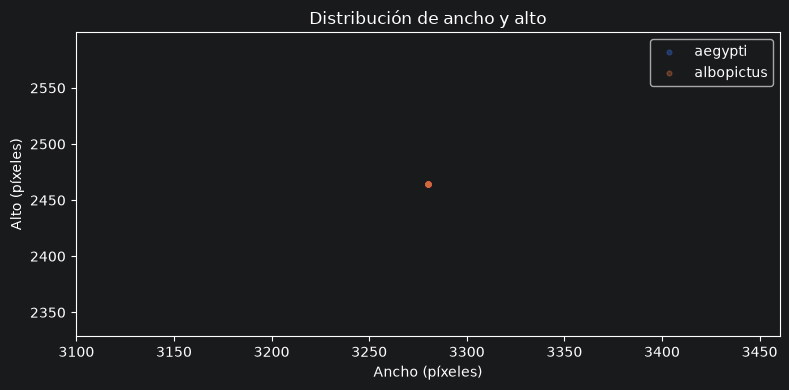

In [9]:
if not df_meta.empty:
    resoluciones = df_meta["Resolución"].value_counts().rename_axis("Resolución")
    display(resoluciones.head(15).reset_index(name="Imágenes"))
    print("Resoluciones diferentes:", len(resoluciones))
    orientacion = np.select(
        [df_meta["Ancho"] == df_meta["Alto"], df_meta["Ancho"] > df_meta["Alto"]],
        ["Cuadrada", "Horizontal"], default="Vertical"
    )
    df_meta["Orientación"] = orientacion
    display(pd.crosstab(df_meta["Orientación"], df_meta["Clase"], margins=True))
    plt.figure(figsize=(8, 4))
    for clase in CLASES:
        sub = df_meta[df_meta["Clase"] == clase]
        plt.scatter(sub["Ancho"], sub["Alto"], s=12, alpha=0.35, label=clase)
    plt.title("Distribución de ancho y alto")
    plt.xlabel("Ancho (píxeles)")
    plt.ylabel("Alto (píxeles)")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 10. Formatos de archivo y consistencia de extensiones

Se comparan la extensión y el formato de imagen reconocido por Pillow para detectar archivos con extensiones incorrectas u otros formatos.

In [10]:
if not df_meta.empty:
    display(pd.crosstab(df_meta["Extension"], df_meta["Clase"], margins=True))
    display(pd.crosstab(df_meta["Formato_real"], df_meta["Clase"], margins=True))
    equivalencias = {
        ".jpg": "JPEG", ".jpeg": "JPEG", ".png": "PNG", ".webp": "WEBP",
        ".bmp": "BMP", ".tif": "TIFF", ".tiff": "TIFF"
    }
    df_meta["Extensión_consistente"] = df_meta.apply(
        lambda r: equivalencias.get(r["Extension"]) == r["Formato_real"], axis=1
    )
    print("Extensiones inconsistentes:", int((~df_meta["Extensión_consistente"]).sum()))
    display(df_meta.loc[~df_meta["Extensión_consistente"],
                         ["Clase", "Ruta_relativa", "Extension", "Formato_real"]].head(10))

Clase,aegypti,albopictus,All
Extension,,,
.jpg,2403,2400,4803
All,2403,2400,4803


Clase,aegypti,albopictus,All
Formato_real,,,
JPEG,2403,2400,4803
All,2403,2400,4803


Extensiones inconsistentes: 0


,Clase,Ruta_relativa,Extension,Formato_real


## 11. Modos y canales de color

Se determina si las imágenes están en RGB, RGBA, escala de grises u otro modo, para orientar su transformación posterior a un número uniforme de canales.

In [11]:
if not df_meta.empty:
    display(pd.crosstab(df_meta["Modo"], df_meta["Clase"], margins=True))
    print("Modos de color distintos:", df_meta["Modo"].nunique())

Clase,aegypti,albopictus,All
Modo,,,
RGB,2403,2400,4803
All,2403,2400,4803


Modos de color distintos: 1


## 12. Tamaño de archivos

Se analiza el peso en MB de las fotografías para detectar archivos atípicamente pequeños o grandes.

,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
aegypti,2403.0,4.028,0.025,3.912,4.014,4.030,4.045,4.115
albopictus,2400.0,4.058,0.025,3.975,4.042,4.059,4.074,4.127


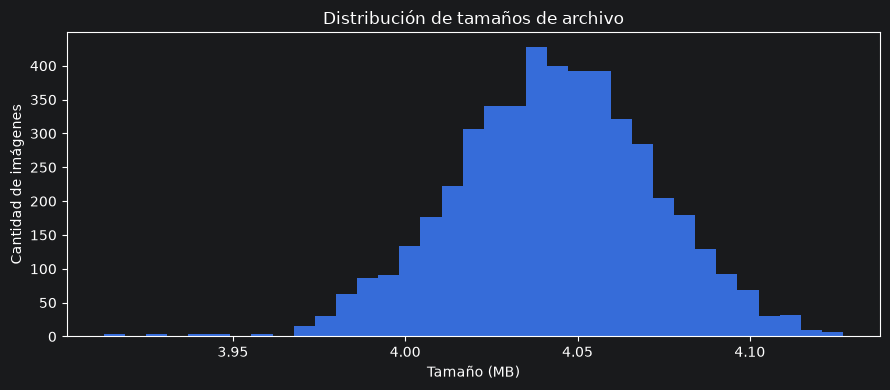

In [12]:
if not df_imagenes.empty:
    display(df_imagenes.groupby("Clase")["Tamaño_MB"].describe().round(3))
    plt.figure(figsize=(9, 4))
    plt.hist(df_imagenes["Tamaño_MB"], bins=35)
    plt.xlabel("Tamaño (MB)")
    plt.ylabel("Cantidad de imágenes")
    plt.title("Distribución de tamaños de archivo")
    plt.tight_layout()
    plt.show()

## 13. Análisis de brillo por especie

Se comparan los valores de iluminación entre ambas clases. Los extremos pueden justificar una revisión visual antes del entrenamiento.

,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
aegypti,2403.0,128.89,3.07,115.20,128.45,129.53,130.56,132.62
albopictus,2400.0,127.31,3.25,116.23,127.46,128.30,129.10,131.39


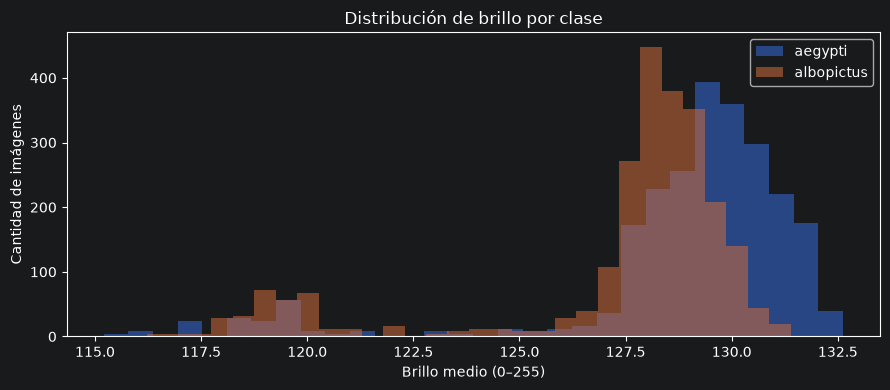

In [13]:
if not df_meta.empty:
    display(df_meta.groupby("Clase")["Brillo"].describe().round(2))
    plt.figure(figsize=(9, 4))
    for clase in CLASES:
        valores = df_meta.loc[df_meta["Clase"] == clase, "Brillo"]
        plt.hist(valores, bins=30, alpha=0.55, label=clase)
    plt.title("Distribución de brillo por clase")
    plt.xlabel("Brillo medio (0–255)")
    plt.ylabel("Cantidad de imágenes")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 14. Análisis de contraste por especie

Se mide la variación de intensidad de cada imagen (desviación estándar en escala de grises) y se comparan las clases.

,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
aegypti,2403.0,16.70,0.65,14.24,16.30,16.69,17.08,18.32
albopictus,2400.0,16.72,0.77,14.17,16.22,16.67,17.18,19.20


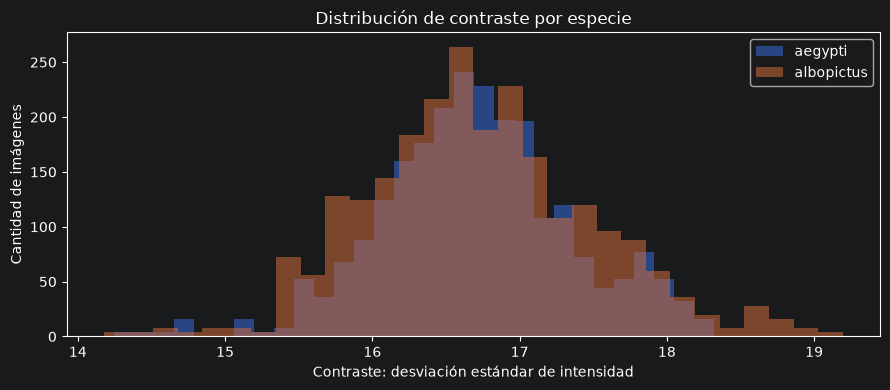

In [14]:
if not df_meta.empty:
    display(df_meta.groupby("Clase")["Contraste"].describe().round(2))
    plt.figure(figsize=(9, 4))
    for clase in CLASES:
        plt.hist(df_meta.loc[df_meta["Clase"] == clase, "Contraste"],
                 bins=30, alpha=0.55, label=clase)
    plt.xlabel("Contraste: desviación estándar de intensidad")
    plt.ylabel("Cantidad de imágenes")
    plt.title("Distribución de contraste por especie")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 15. Análisis de nitidez por especie

Se utiliza la varianza del Laplaciano en miniaturas de 128 × 128. Un valor bajo puede sugerir desenfoque, pero también depende de textura, resolución y encuadre; no es un criterio automático de eliminación.

,count,mean,std,min,25%,50%,75%,max
Clase,,,,,,,,
aegypti,2403.0,139.50,30.32,31.75,118.44,137.39,159.91,257.74
albopictus,2400.0,145.69,45.13,54.96,113.79,138.52,171.85,346.03


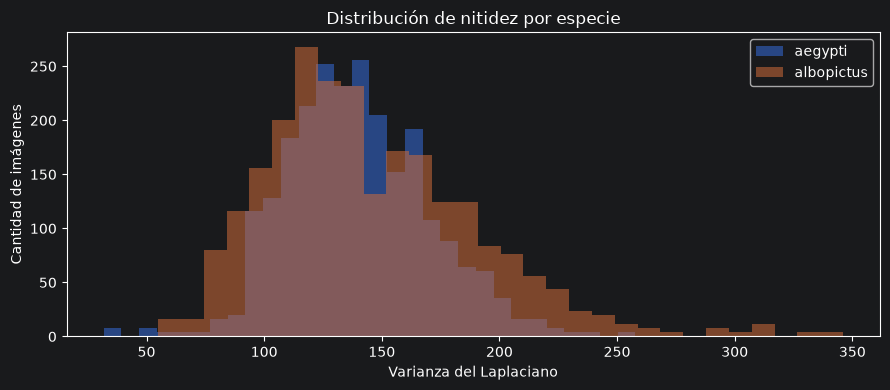

In [15]:
if not df_meta.empty:
    display(df_meta.groupby("Clase")["Nitidez"].describe().round(2))
    plt.figure(figsize=(9, 4))
    for clase in CLASES:
        plt.hist(df_meta.loc[df_meta["Clase"] == clase, "Nitidez"],
                 bins=30, alpha=0.55, label=clase)
    plt.title("Distribución de nitidez por especie")
    plt.xlabel("Varianza del Laplaciano")
    plt.ylabel("Cantidad de imágenes")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 16. Revisión visual de imágenes extremas

Se muestran ejemplos con menor nitidez y con brillo extremo. Este paso ayuda a interpretar las mediciones; ninguna imagen se elimina automáticamente.

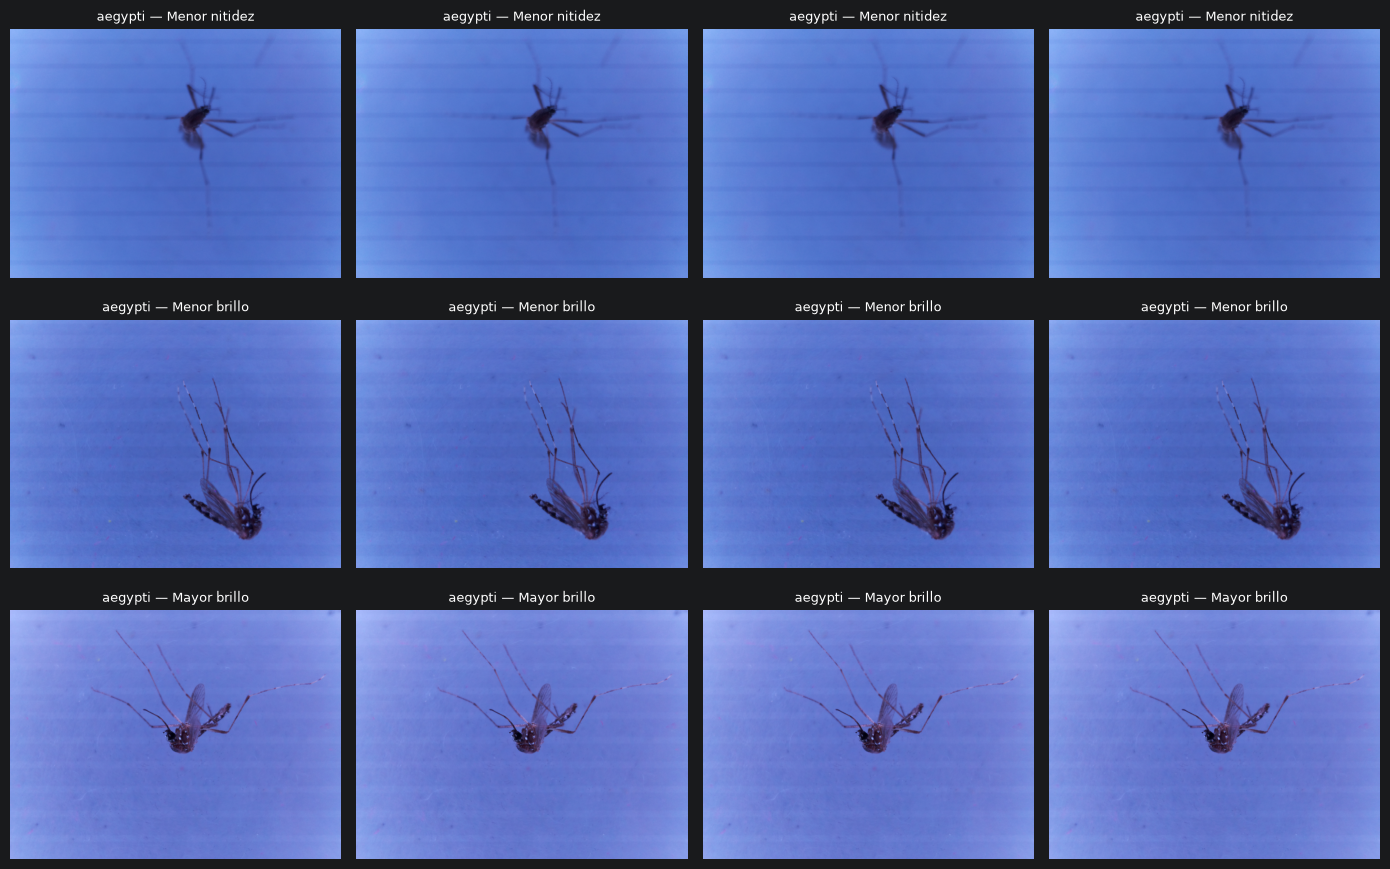

In [16]:
if not df_meta.empty:
    extremos = [
        ("Menor nitidez", df_meta.nsmallest(4, "Nitidez")),
        ("Menor brillo", df_meta.nsmallest(4, "Brillo")),
        ("Mayor brillo", df_meta.nlargest(4, "Brillo")),
    ]
    fig, axes = plt.subplots(3, 4, figsize=(14, 9))
    for fila, (titulo, tabla) in enumerate(extremos):
        for ax in axes[fila]:
            ax.axis("off")
        for ax, (_, reg) in zip(axes[fila], tabla.iterrows()):
            with Image.open(reg["Archivo"]) as imagen:
                ax.imshow(imagen.convert("RGB"))
            ax.set_title(f"{reg['Clase']} — {titulo}", fontsize=9)
    plt.tight_layout()
    plt.show()

## 17. Distribución de intensidades RGB (muestra reproducible)

Se analizan los valores de los tres canales de color de una **muestra de hasta 50 imágenes por clase**. Es un análisis complementario para observar diferencias de iluminación y color, no una clasificación de especies.

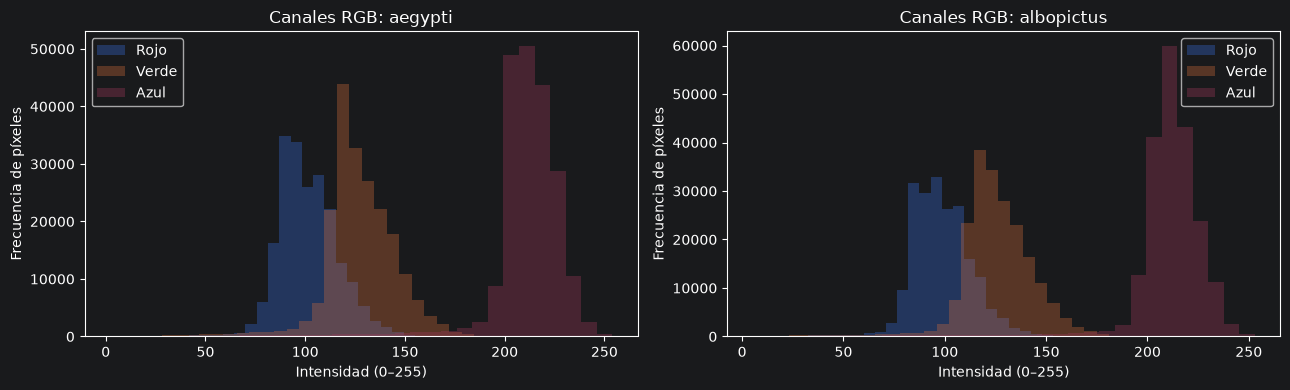

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, clase in zip(axes, CLASES):
    sub = df_meta[df_meta["Clase"] == clase]
    muestra = sub.sample(n=min(len(sub), 50), random_state=42)
    canales = [[], [], []]
    for archivo in muestra["Archivo"]:
        with Image.open(archivo) as img:
            pixels = np.asarray(img.convert("RGB").resize((64, 64)))
        for canal in range(3):
            canales[canal].append(pixels[:, :, canal].ravel())
    for i, nombre in enumerate(["Rojo", "Verde", "Azul"]):
        if canales[i]:
            ax.hist(np.concatenate(canales[i]), bins=30, alpha=0.35, label=nombre)
    ax.set_title(f"Canales RGB: {clase}")
    ax.set_xlabel("Intensidad (0–255)")
    ax.set_ylabel("Frecuencia de píxeles")
    ax.legend()
plt.tight_layout()
plt.show()

## 18. Detección de duplicados exactos (SHA-256)

Se calcula una huella SHA-256 por archivo. Si dos fotografías tienen exactamente el mismo contenido binario, se marcan como duplicadas. No se borra ningún archivo.

In [18]:
def sha256_archivo(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b""):
            h.update(bloque)
    return h.hexdigest()

df_meta["SHA256"] = df_meta["Archivo"].map(sha256_archivo)
grupos_sha = df_meta.groupby("SHA256").agg(
    Repeticiones=("Archivo", "size"),
    Clases=("Clase", lambda x: ", ".join(sorted(set(x)))),
    Archivos=("Ruta_relativa", lambda x: " | ".join(x))
)
grupos_sha = grupos_sha[grupos_sha["Repeticiones"] > 1]
numero_duplicados = int((grupos_sha["Repeticiones"] - 1).sum())
print("Imágenes analizadas:", len(df_meta))
print("Duplicados exactos adicionales:", numero_duplicados)
print("Grupos con duplicados exactos:", len(grupos_sha))
display(grupos_sha.head(10))

Imágenes analizadas: 4803
Duplicados exactos adicionales: 3
Grupos con duplicados exactos: 3


,Repeticiones,Clases,Archivos
SHA256,,,
181d199579b58f4b576c6533071eb49ddb57f4e107b4c4b2da61cc759bcf603e,2,aegypti,aegypti\aegypti\aegypti_0\aegypti29b - Copy.jp...
2d1455f0625c4ef880f6b3f51a76aa454b417f6ceb5cd99d4158891e4cc94d80,2,aegypti,aegypti\aegypti\aegypti_0\aegypti30d - Copy.jp...
da41cb32d9b6d192c7038c4856ddeb980ba41bf0052ee6edf907dbead3233432,2,aegypti,aegypti\aegypti\aegypti_0\aegypti32b - Copy.jp...


## 19. Posibles duplicados visuales (dHash)

Se agrupan imágenes cuyo **dHash sea idéntico**. Estas coincidencias son solo **candidatos visuales** que deben revisarse; un mismo hash no garantiza que las fotografías sean iguales. No se cuentan aquí los duplicados SHA-256 ya identificados como si fueran hallazgos nuevos.

In [19]:
# Un registro representativo por hash exacto, para no repetir idénticos ya hallados
unicos_exactos = df_meta.drop_duplicates(subset="SHA256")
grupos_visual = unicos_exactos.groupby("dHash").agg(
    Repeticiones=("Archivo", "size"),
    Clases=("Clase", lambda x: ", ".join(sorted(set(x)))),
    Archivos=("Ruta_relativa", lambda x: " | ".join(x))
)
grupos_visual = grupos_visual[grupos_visual["Repeticiones"] > 1]
candidatos_visuales = int((grupos_visual["Repeticiones"] - 1).sum())
print("Candidatos visuales adicionales (dHash idéntico):", candidatos_visuales)
print("Grupos de candidatos:", len(grupos_visual))
display(grupos_visual.head(10))

Candidatos visuales adicionales (dHash idéntico): 4295
Grupos de candidatos: 505


,Repeticiones,Clases,Archivos
dHash,,,
0303030101050707,4,aegypti,aegypti\aegypti\aegypti_0\aegypti21b.jpg | aeg...
030303030b0f0f07,4,aegypti,aegypti\aegypti\aegypti_0\aegypti33b.jpg | aeg...
030307070301070f,4,albopictus,albopictus\albopictus\albopictus_0\albopictus4...
03030b0b0b03090b,4,aegypti,aegypti\aegypti\aegypti_0\aegypti127b.jpg | ae...
03070b07070f0f07,4,albopictus,albopictus\albopictus\albopictus_0\albopictus1...
03070f0f0f070707,4,albopictus,albopictus\albopictus\albopictus_0\albopictus1...
03070f0f0f0f0f0f,4,aegypti,aegypti\aegypti\aegypti_0\aegypti101c.jpg | ae...
0703030707070707,8,aegypti,aegypti\aegypti\aegypti_0\aegypti11b.jpg | aeg...
0703030707170f0f,4,aegypti,aegypti\aegypti\aegypti_0\aegypti25b.jpg | aeg...


## 20. Duplicados o coincidencias entre clases

Se revisa si un archivo idéntico o un candidato visual aparece etiquetado en clases diferentes. Estos casos requieren inspección para prevenir etiquetas contradictorias o errores al separar entrenamiento y prueba.

In [20]:
conflictos_sha = grupos_sha[grupos_sha["Clases"].str.contains(",")]
conflictos_visual = grupos_visual[grupos_visual["Clases"].str.contains(",")]
print("Grupos SHA-256 presentes en ambas clases:", len(conflictos_sha))
print("Grupos dHash idénticos entre clases:", len(conflictos_visual))
display(conflictos_sha.head(10))
display(conflictos_visual.head(10))

Grupos SHA-256 presentes en ambas clases: 0
Grupos dHash idénticos entre clases: 131


,Repeticiones,Clases,Archivos
SHA256,,,


,Repeticiones,Clases,Archivos
dHash,,,
0707070303070707,8,"aegypti, albopictus",aegypti\aegypti\aegypti_0\aegypti40b.jpg | aeg...
070707030707070f,8,"aegypti, albopictus",aegypti\aegypti\aegypti_0\aegypti7b.jpg | aegy...
0707070707030707,12,"aegypti, albopictus",aegypti\aegypti\aegypti_0\aegypti42d.jpg | aeg...
070707070707030f,8,"aegypti, albopictus",aegypti\aegypti\aegypti_0\aegypti89d.jpg | aeg...
0707070707070707,132,"aegypti, albopictus",aegypti\aegypti\aegypti_0\aegypti104d.jpg | ae...
070707070707070f,48,"aegypti, albopictus",aegypti\aegypti\aegypti_0\aegypti128b.jpg | ae...
0707070707070b07,8,"aegypti, albopictus",aegypti\aegypti\aegypti_0\aegypti92c.jpg | aeg...
0707070707070f07,32,"aegypti, albopictus",aegypti\aegypti\aegypti_0\aegypti36a.jpg | aeg...
0707070707070f0f,84,"aegypti, albopictus",aegypti\aegypti\aegypti_0\aegypti104a.jpg | ae...


## 21. Indicios de imágenes aumentadas en nombres de archivo

Se buscan nombres que contienen palabras como `aug`, `rot`, `flip` o `mirror`, frecuentemente utilizadas en aumentos de datos. **La ausencia de estas palabras no implica que no existan imágenes aumentadas**, ya que las transformaciones pueden haberse guardado con cualquier nombre.

In [21]:
patron = re.compile(r"aug(?:ment)?|rot(?:ate|ation)?|flip|mirror|zoom|shear", re.IGNORECASE)
df_nombres = df_meta[["Clase", "Nombre", "Ruta_relativa"]].copy()
df_nombres["Indicio_nombre_aumentado"] = df_nombres["Nombre"].map(
    lambda s: bool(patron.search(Path(s).stem))
)
print("Archivos con indicios en el nombre:", int(df_nombres["Indicio_nombre_aumentado"].sum()))
display(pd.crosstab(df_nombres["Clase"], df_nombres["Indicio_nombre_aumentado"]))
display(df_nombres[df_nombres["Indicio_nombre_aumentado"]].head(15))

Archivos con indicios en el nombre: 0


Indicio_nombre_aumentado,False
Clase,
aegypti,2403
albopictus,2400


,Clase,Nombre,Ruta_relativa,Indicio_nombre_aumentado


## 22. Nombres de archivo repetidos y organización

Se comprueba si hay nombres iguales almacenados en rutas distintas. Dos archivos pueden tener el mismo nombre y contenidos diferentes, por lo que esto no equivale a duplicidad exacta.

In [22]:
repetidos_nombre = df_imagenes[df_imagenes.duplicated("Nombre", keep=False)]
print("Imágenes con nombre compartido:", len(repetidos_nombre))
print("Nombres distintos repetidos:", repetidos_nombre["Nombre"].nunique())
display(repetidos_nombre[["Clase", "Nombre", "Ruta_relativa"]].head(15))

Imágenes con nombre compartido: 4800
Nombres distintos repetidos: 1200


,Clase,Nombre,Ruta_relativa
0,aegypti,aegypti100a.jpg,aegypti\aegypti\aegypti_0\aegypti100a.jpg
1,aegypti,aegypti100b.jpg,aegypti\aegypti\aegypti_0\aegypti100b.jpg
2,aegypti,aegypti100c.jpg,aegypti\aegypti\aegypti_0\aegypti100c.jpg
3,aegypti,aegypti101b.jpg,aegypti\aegypti\aegypti_0\aegypti101b.jpg
4,aegypti,aegypti101c.jpg,aegypti\aegypti\aegypti_0\aegypti101c.jpg
5,aegypti,aegypti101d.jpg,aegypti\aegypti\aegypti_0\aegypti101d.jpg
6,aegypti,aegypti102a.jpg,aegypti\aegypti\aegypti_0\aegypti102a.jpg
7,aegypti,aegypti102b.jpg,aegypti\aegypti\aegypti_0\aegypti102b.jpg
8,aegypti,aegypti102c.jpg,aegypti\aegypti\aegypti_0\aegypti102c.jpg
9,aegypti,aegypti102d.jpg,aegypti\aegypti\aegypti_0\aegypti102d.jpg


## 23. Revisión final de clases y balance del dataset

Se calcula el equilibrio final tomando únicamente las fotografías **válidas** de `aegypti` y `albopictus`. Se muestran estadísticas y porcentajes sin alterar el conjunto original.

In [23]:
conteo_valido = df_meta[df_meta["Clase"].isin(CLASES)]["Clase"].value_counts().reindex(CLASES, fill_value=0)
tabla_balance = pd.DataFrame({
    "Clase": CLASES,
    "Imágenes válidas": [int(conteo_valido.loc[c]) for c in CLASES]
})
tabla_balance["Porcentaje (%)"] = (
    tabla_balance["Imágenes válidas"] / max(tabla_balance["Imágenes válidas"].sum(), 1) * 100
).round(2)
mayor = int(tabla_balance["Imágenes válidas"].max())
menor = int(tabla_balance["Imágenes válidas"].min())
relacion = mayor/menor if menor > 0 else float("nan")
display(tabla_balance)
print(f"Relación mayoritaria/minoritaria: {relacion:.2f}:1" if menor else
      "No es posible calcular la relación (falta una clase).")

,Clase,Imágenes válidas,Porcentaje (%)
0,aegypti,2403,50.03
1,albopictus,2400,49.97


Relación mayoritaria/minoritaria: 1.00:1


## 24. Revisión de compatibilidad con las clases de VectorIA

El proyecto final requiere tres clases: *Aedes aegypti*, *Aedes albopictus* y *Culex*. Este dataset contiene fotografías de las dos primeras; `Culex` deberá aportarse desde otros datasets y no puede obtenerse de esta carpeta.

In [24]:
objetivo_vectoria = ["aegypti", "albopictus", "culex"]
presentes = set(df_meta["Clase"].str.lower())
compatibilidad = pd.DataFrame({
    "Clase requerida": objetivo_vectoria,
    "Disponible aquí": ["Sí" if c in presentes else "No" for c in objetivo_vectoria],
    "Imágenes válidas": [int((df_meta["Clase"].str.lower() == c).sum()) for c in objetivo_vectoria],
})
display(compatibilidad)

,Clase requerida,Disponible aquí,Imágenes válidas
0,aegypti,Sí,2403
1,albopictus,Sí,2400
2,culex,No,0


## 25. Resumen automático del EDA

Se reúnen las métricas más importantes calculadas **a partir de tus imágenes reales**. Este apartado sirve de base para redactar la conclusión final. No genera conclusiones automáticas.

In [25]:
resumen = [
    ("Total de imágenes encontradas", len(df_imagenes)),
    ("Clases identificadas", df_meta.loc[df_meta["Clase"] != "SIN_CLASE", "Clase"].nunique()),
    ("Imágenes sin clase identificada", int((df_imagenes["Clase"] == "SIN_CLASE").sum())),
    ("Imágenes válidas", len(df_meta)),
    ("Imágenes dañadas", len(df_errores)),
    ("Resoluciones diferentes", df_meta["Resolución"].nunique()),
    ("Modos de color diferentes", df_meta["Modo"].nunique()),
    ("Formatos reales diferentes", df_meta["Formato_real"].nunique()),
    ("Extensiones inconsistentes", int((~df_meta["Extensión_consistente"]).sum())),
    ("Duplicados exactos adicionales", numero_duplicados),
    ("Grupos de duplicados entre clases", len(conflictos_sha)),
    ("Candidatos visuales adicionales (dHash)", candidatos_visuales),
    ("Grupos dHash entre clases", len(conflictos_visual)),
    ("Imágenes con nombres compartidos", len(repetidos_nombre)),
    ("Indicios de aumento en nombres", int(df_nombres["Indicio_nombre_aumentado"].sum())),
    ("Brillo promedio", round(df_meta["Brillo"].mean(), 2)),
    ("Contraste promedio", round(df_meta["Contraste"].mean(), 2)),
    ("Nitidez mediana", round(df_meta["Nitidez"].median(), 2)),
    ("Relación mayoritaria/minoritaria", round(relacion, 2) if menor else None),
]
tabla_resumen = pd.DataFrame(resumen, columns=["Indicador", "Resultado"])
display(tabla_resumen)
print("Distribución final por clase:")
display(tabla_balance)

,Indicador,Resultado
0,Total de imágenes encontradas,4803.00
1,Clases identificadas,2.00
2,Imágenes sin clase identificada,0.00
3,Imágenes válidas,4803.00
4,Imágenes dañadas,0.00
5,Resoluciones diferentes,1.00
6,Modos de color diferentes,1.00
7,Formatos reales diferentes,1.00
8,Extensiones inconsistentes,0.00
9,Duplicados exactos adicionales,3.00


Distribución final por clase:


,Clase,Imágenes válidas,Porcentaje (%)
0,aegypti,2403,50.03
1,albopictus,2400,49.97



## 26. Conclusiones generales del EDA

El análisis exploratorio del dataset Kaggle permitió evaluar las características, distribución, calidad e integridad de las imágenes de Aedes aegypti y Aedes albopictus, identificando aspectos importantes para su posterior utilización en el entrenamiento de la CNN del proyecto VectorIA.

### 26.1. Principales hallazgos

1. **Cantidad de imágenes:** se analizaron 4.803 imágenes correspondientes a dos especies: Aedes aegypti y Aedes albopictus. Todas las imágenes fueron identificadas correctamente según la estructura de carpetas.

2. **Distribución de clases:** se obtuvo una relación de desbalance de 1,00:1, lo que indica que ambas especies tienen una representación prácticamente equilibrada. Esto es favorable para el entrenamiento, ya que reduce el riesgo de favorecer una clase únicamente por su cantidad de imágenes.

3. **Dimensiones:** se identificó una única resolución en las 4.803 imágenes. Esto demuestra que el dataset mantiene dimensiones uniformes, aunque será necesario adaptarlas al tamaño de entrada requerido por la CNN.

4. **Formatos y canales de color:** se encontró un único formato real y un único modo de color. No se detectaron extensiones inconsistentes, lo que facilita la preparación de las imágenes.

5. **Brillo:** el brillo promedio fue de 128,10 en una escala de 0 a 255. La mayoría de las imágenes presenta valores cercanos a este promedio. Los gráficos muestran que Aedes aegypti tiende a concentrarse en valores ligeramente superiores a Aedes albopictus, aunque ambas distribuciones se superponen.

6. **Contraste:** el contraste promedio fue de 16,71, lo que indica una variación relativamente baja de intensidad en las fotografías. Esta característica podría dificultar la identificación de algunos detalles visuales de los mosquitos.

7. **Nitidez:** se obtuvo una mediana de 137,77 mediante la varianza del Laplaciano. Este indicador permite comparar el nivel de detalle de las imágenes, aunque por sí solo no determina si una fotografía tiene una calidad adecuada.

8. **Tamaño de archivos:** las imágenes presentan tamaños relativamente uniformes, concentrados aproximadamente alrededor de los 4 MB, con pequeñas variaciones entre archivos.

9. **Integridad:** las 4.803 imágenes se procesaron correctamente, sin encontrar archivos dañados ni problemas de lectura.

10. **Duplicados exactos:** se identificaron 3 archivos exactamente duplicados. No se detectaron grupos de duplicados exactos entre especies diferentes.

11. **Posibles duplicados visuales:** el análisis mediante dHash identificó 4.295 candidatos adicionales a imágenes visualmente similares. Esta cantidad es considerable y requiere una revisión más detallada, ya que la similitud perceptual no demuestra necesariamente que las fotografías sean duplicadas.

12. **Similitudes entre especies:** se identificaron 131 grupos de dHash que contienen imágenes de ambas clases. Esto no confirma errores de etiquetado, pero representa un hallazgo importante que debe investigarse para evitar confusiones durante el entrenamiento.

13. **Nombres de archivos:** se encontraron 4.800 coincidencias de nombres entre las carpetas de ambas especies. Esto podría provocar conflictos si las imágenes se combinan en una sola carpeta sin conservar su identificación de origen.

14. **Indicios de aumento de datos:** no se encontraron indicadores de aumento artificial en los nombres de los archivos. Sin embargo, esto no permite descartar que algunas imágenes hayan sido generadas mediante transformaciones.

### 26.2. Recomendaciones para el entrenamiento

- **Revisar duplicados:** identificar los 3 duplicados exactos y examinar los 4.295 candidatos visualmente similares antes de preparar los conjuntos de entrenamiento y prueba.

- **Examinar similitudes entre clases:** revisar especialmente los 131 grupos de dHash que contienen imágenes de ambas especies, para determinar si existen errores de etiquetado o fotografías visualmente parecidas.

- **Evitar fugas de información:** si se confirma que distintas imágenes provienen de una misma fotografía original, mantenerlas en el mismo conjunto al dividir los datos en entrenamiento, validación y prueba.

- **Conservar el equilibrio:** mantener una distribución adecuada entre Aedes aegypti y Aedes albopictus durante la preparación de los datos.

- **Estandarizar las imágenes:** adaptar las dimensiones a los requisitos de la CNN, considerando la resolución de 128 × 128 píxeles propuesta por el profesor.

- **Evaluar la calidad visual:** revisar las fotografías con niveles extremos de brillo, contraste y nitidez antes de decidir si necesitan algún tratamiento adicional.

- **Mantener etiquetas y nombres únicos:** conservar la identificación de cada especie y evitar sobrescribir archivos cuando se combinen diferentes datasets.

- **Verificar posibles imágenes aumentadas:** analizar si las fotografías visualmente similares corresponden a transformaciones de imágenes originales, aunque sus nombres no lo indiquen.

- **Complementar otros datasets:** utilizar las imágenes de Aedes aegypti y Aedes albopictus para fortalecer la representación de ambas especies en el conjunto general de VectorIA.

- **Evaluar por especie:** utilizar el F1-score macro y analizar el rendimiento individual de cada clase durante la evaluación del modelo.

### 26.3. Conclusión final

El dataset Kaggle presenta características favorables para el desarrollo de la CNN de VectorIA, principalmente por su distribución equilibrada entre Aedes aegypti y Aedes albopictus, uniformidad de dimensiones y formatos, y ausencia de archivos dañados.

Sin embargo, el análisis identificó una cantidad considerable de posibles similitudes visuales entre fotografías, incluyendo grupos que contienen imágenes de especies diferentes. Estos resultados requieren una revisión adicional antes del entrenamiento para determinar si corresponden a imágenes repetidas, transformaciones o semejanzas naturales entre los mosquitos.

También se observaron diferencias moderadas de iluminación y niveles relativamente bajos de contraste, aspectos que podrían influir en la identificación de características morfológicas.

En comparación con los datasets anteriores, Kaggle ofrece una ventaja importante: una representación prácticamente equilibrada entre las dos especies de Aedes que necesita el proyecto. Esto puede contribuir a complementar las pocas imágenes de Aedes aegypti disponibles en Mosquito Alert 2023.

En conclusión, el dataset es una fuente valiosa para el entrenamiento de la CNN, pero se recomienda revisar las similitudes visuales detectadas, controlar posibles duplicaciones y garantizar una correcta separación de los datos antes de incorporarlo al conjunto general de imágenes de VectorIA.
